In [1]:
# make sure you ran workspace\ibm-qiskit-login.py first


print("let's try qiskit")
# https://docs.quantum.ibm.com/guides/hello-world

let's try qiskit


In [2]:
import qiskit_ibm_runtime
qiskit_ibm_runtime.version.get_version_info()

'0.38.0'

In [3]:
import qiskit
qiskit.version.get_version_info()

'2.0.0'

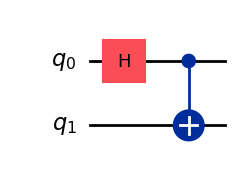

In [5]:
# based on  https://docs.quantum.ibm.com/guides/hello-world
# 
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
#from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
 
# Create a new circuit with two qubits
qc = QuantumCircuit(2)
 
# Add a Hadamard gate to qubit 0
qc.h(0)
 
# Perform a controlled-X gate on qubit 1, controlled by qubit 0
qc.cx(0, 1)
 
# Return a drawing of the circuit using MatPlotLib ("mpl").
# These guides are written by using Jupyter notebooks, which
# display the output of the last line of each cell.
# If you're running this in a script, use `print(qc.draw())` to
# print a text drawing.
qc.draw("mpl")

C:\Users\thromadka\AppData\Local\Temp\ipykernel_13360\3818451295.py:13: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService()


job id: d0kr67ghp5pg0080q8qg
PrimitiveResult([SamplerPubResult(data=DataBin(meas=BitArray(<shape=(), num_shots=4096, num_bits=5>)), metadata={'circuit_metadata': {}})], metadata={'execution': {'execution_spans': ExecutionSpans([DoubleSliceSpan(<start='2025-05-16 18:25:37', stop='2025-05-16 18:25:39', size=4096>)])}, 'version': 2})


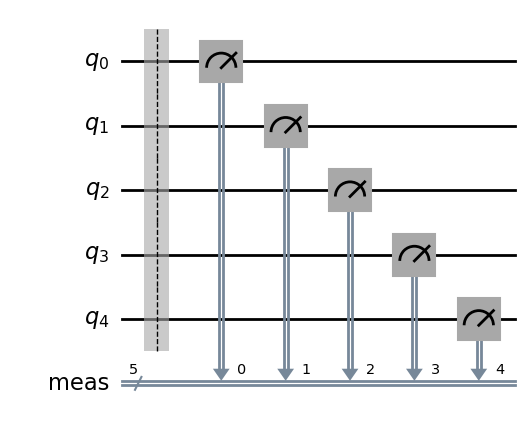

In [7]:



from qiskit.circuit import QuantumCircuit

from qiskit_ibm_runtime import QiskitRuntimeService

#from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator, SamplerV2 as Sampler

# Create empty circuit
example_circuit = QuantumCircuit(5)
example_circuit.measure_all()
 
# You'll need to specify the credentials when initializing QiskitRuntimeService, if they were not previously saved.
service = QiskitRuntimeService()
backend = service.least_busy(operational=True, simulator=False)
 
sampler = Sampler(backend)
job = sampler.run([example_circuit])
print(f"job id: {job.job_id()}")
result = job.result()
print(result)

example_circuit.draw("mpl") 


In [7]:
# Set up six different observables.
 
observables_labels = ["IZ", "IX", "ZI", "XI", "ZZ", "XX"]
observables = [SparsePauliOp(label) for label in observables_labels]

C:\Users\thromadka\AppData\Local\Temp\ipykernel_25560\1955996326.py:4: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService()


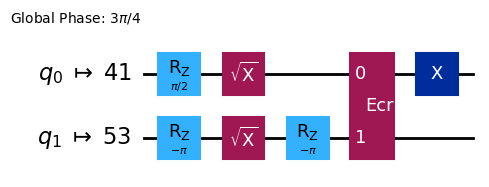

In [8]:
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.transpiler import generate_preset_pass_manager

service = QiskitRuntimeService()
 
backend = service.least_busy(simulator=False, operational=True)
 
# Convert to an ISA circuit and layout-mapped observables.
#pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
pm = generate_preset_pass_manager(backend=backend)
isa_circuit = pm.run(qc)
 
isa_circuit.draw("mpl", idle_wires=False)

In [9]:
# Construct the Estimator instance.
 
estimator = Estimator(mode=backend)
estimator.options.resilience_level = 1
estimator.options.default_shots = 5000
 
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
# One pub, with one circuit to run against five different observables.
job = estimator.run([(isa_circuit, mapped_observables)])
 
# Use the job ID to retrieve your job data later
print(f">>> Job ID: {job.job_id()}")

>>> Job ID: d0k71k6crrag008nbpvg


In [10]:
# This is the result of the entire submission.  You submitted one Pub,
# so this contains one inner result (and some metadata of its own).
job_result = job.result()
 
# This is the result from our single pub, which had six observables,
# so contains information on all six.
pub_result = job.result()[0]

In [12]:
# https://quantumcomputing.stackexchange.com/questions/39185/generate-preset-pass-manager-and-sampler-api-usage-in-ibm-qiskit

# Optimize problem for quantum execution
service = QiskitRuntimeService(channel = 'ibm_quantum', instance="ibm-q/open/main")
backend = service.least_busy(operational=True, simulator=False)
#backend = service.least_busy(simulator=True)
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)

sampler = Sampler(mode=backend)
sampler.options.default_shots = 100000
job = sampler.run([isa_circuit])
print(f"Job ID is {job.job_id()}")
pub_result = job.result()[0]

# ERROR
# print(f"Counts for the meas output register: {pub_result.data.meas.get_counts()}")


C:\Users\thromadka\AppData\Local\Temp\ipykernel_25560\1126857547.py:4: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel = 'ibm_quantum', instance="ibm-q/open/main")
C:\Users\thromadka\AppData\Local\Programs\Python\Python310\lib\site-packages\qiskit_ibm_runtime\utils\validations.py:40: UserWarning: The 0-th circuit has no output classical registers so the result will be empty. Did you mean to add measurement instructions?
  warnings.warn(


Job ID is d0k72xvehmr0008gxhf0


AttributeError: 'DataBin' object has no attribute 'meas'

In [24]:
print(job.result())

PrimitiveResult([PubResult(data=DataBin(evs=np.ndarray(<shape=(6,), dtype=float64>), stds=np.ndarray(<shape=(6,), dtype=float64>), shape=(6,)), metadata={'target_precision': 0.015625, 'shots': 4096, 'circuit_metadata': {}})], metadata={'version': 2})


In [20]:
from qiskit.quantum_info import SparsePauliOp 

# Set up six different observables.
observables_labels = ["IZ", "IX", "ZI", "XI", "ZZ", "XX"]
observables = [SparsePauliOp(label) for label in observables_labels]

In [21]:
# Use the following code instead if you want to run on a simulator:
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
backend = FakeAlmadenV2()
estimator = Estimator(backend)
 
# Convert to an ISA circuit and layout-mapped observables.
 
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
job = estimator.run([(isa_circuit, mapped_observables)])
result = job.result()
 
# This is the result of the entire submission.  You submitted one Pub,
# so this contains one inner result (and some metadata of its own).
 
job_result = job.result()
 
# This is the result from our single pub, which had five observables,
# so contains information on all five.
 
pub_result = job.result()[0]

In [26]:
# https://docs.quantum.ibm.com/api/qiskit/transpiler

# the following code is meant to test the preset-pass-manager

from qiskit.circuit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
 
# Any abstract circuit you want:
abstract = QuantumCircuit(2)
abstract.h(0)
abstract.cx(0, 1)

service = QiskitRuntimeService()
backend = service.least_busy(simulator=False, operational=True)

# Any method you like to retrieve the backend you want to run on:
#backend = QiskitRuntimeService().backend("some-backend")
 
# Create the pass manager for the transpilation ...
pm = generate_preset_pass_manager(backend=backend)
# ... and use it (as many times as you like).
physical = pm.run(abstract)

C:\Users\thromadka\AppData\Local\Temp\ipykernel_25560\3017019300.py:14: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService()


In [28]:
# https://quantumcomputing.stackexchange.com/questions/39185/generate-preset-pass-manager-and-sampler-api-usage-in-ibm-qiskit

from qiskit import QuantumCircuit, transpile #, assemble
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
# https://github.com/Qiskit/qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# Save an IBM Cloud account.
#QiskitRuntimeService.save_account(channel="ibm_quantum", token="Add_your_key", overwrite=True)


# Read default credentials from disk
service = QiskitRuntimeService(channel = 'ibm_quantum')

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()
print(qc.draw())



C:\Users\thromadka\AppData\Local\Temp\ipykernel_25560\1167419243.py:13: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel = 'ibm_quantum')


        ┌───┐      ░ ┌─┐   
   q_0: ┤ H ├──■───░─┤M├───
        └───┘┌─┴─┐ ░ └╥┘┌─┐
   q_1: ─────┤ X ├─░──╫─┤M├
             └───┘ ░  ║ └╥┘
meas: 2/══════════════╩══╩═
                      0  1 
Job ID is d0k77dn8jzxg008n4fgg
Counts for the meas output register: {'11': 47596, '00': 40047, '01': 7509, '10': 4848}


In [29]:
# Optimize problem for quantum execution
backend = service.least_busy(operational=True, simulator=False)
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)

sampler = Sampler(mode=backend)
sampler.options.default_shots = 100000
job = sampler.run([isa_circuit])
print(f"Job ID is {job.job_id()}")
pub_result = job.result()[0]
print(f"Counts for the meas output register: {pub_result.data.meas.get_counts()}")

Job ID is d0k786rvpqf00081003g
Counts for the meas output register: {'10': 5659, '00': 38702, '11': 46560, '01': 9079}


In [4]:
# new!  test boolean op circuits
# Part A - set up 

from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit import QuantumCircuit, transpile #, assemble
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator, SamplerV2 as Sampler

# Read default credentials from disk
service = QiskitRuntimeService(channel = 'ibm_quantum')

qc = QuantumCircuit(6)
#qc.x(0)
qc.x(1)
#qc.x(2)
#qc.x(3)

qc.cx(0, 4)
qc.cx(1, 4)
qc.cx(2, 5)
qc.cx(3, 5)


qc.barrier()
qc.cx(4,5)

#qc.mcx([0,1],2)

qc.measure_all()
print(qc.draw())

C:\Users\thromadka\AppData\Local\Temp\ipykernel_19428\1507800428.py:10: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel = 'ibm_quantum')


                             ░       ░ ┌─┐               
   q_0: ───────■─────────────░───────░─┤M├───────────────
        ┌───┐  │             ░       ░ └╥┘┌─┐            
   q_1: ┤ X ├──┼────■────────░───────░──╫─┤M├────────────
        └───┘  │    │        ░       ░  ║ └╥┘┌─┐         
   q_2: ──■────┼────┼────────░───────░──╫──╫─┤M├─────────
          │    │    │        ░       ░  ║  ║ └╥┘┌─┐      
   q_3: ──┼────┼────┼────■───░───────░──╫──╫──╫─┤M├──────
          │  ┌─┴─┐┌─┴─┐  │   ░       ░  ║  ║  ║ └╥┘┌─┐   
   q_4: ──┼──┤ X ├┤ X ├──┼───░───■───░──╫──╫──╫──╫─┤M├───
        ┌─┴─┐└───┘└───┘┌─┴─┐ ░ ┌─┴─┐ ░  ║  ║  ║  ║ └╥┘┌─┐
   q_5: ┤ X ├──────────┤ X ├─░─┤ X ├─░──╫──╫──╫──╫──╫─┤M├
        └───┘          └───┘ ░ └───┘ ░  ║  ║  ║  ║  ║ └╥┘
meas: 6/════════════════════════════════╩══╩══╩══╩══╩══╩═
                                        0  1  2  3  4  5 


In [ ]:
# Part B - run job
from qiskit.visualization import plot_histogram

# Optimize problem for quantum execution
backend = service.least_busy(operational=True, simulator=False)
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)

sampler = Sampler(mode=backend)
sampler.options.default_shots = 5000  #1000 is enough for the simple tests, #10000 for 4-qb MCX
job = sampler.run([isa_circuit])
print(f"Job ID is {job.job_id()}")
pub_result = job.result()[0]
print(f"Counts for the meas output register: {pub_result.data.meas.get_counts()}")


plot_histogram(pub_result.data.meas.get_counts())

Job ID is d0w8q4c4mb60008xvpr0
